In [9]:
"""
File: spam_gridsearch.py
Author: Matthew Ogden
Email: ogdenm12@gmail.com
Github: mbogden
Created: 2025-Feb-12

Description: During the TNG to SPAM unit conversion process, I discovered
    that the default SPAM hyperparameters were not optimal.

References: 
- Sections of this code were written with the assistance of ChatGPT made by OpenAI.
- TNG50 Simulation Data
    - Nelson, D. et al. (2015). The Illustris Simulation: Public Data Release. Astronomy and Computing, 13, 12–37. https://doi.org/10.1016/j.ascom.2015.09.003
    - Nelson, D. et al. (2019). First results from the TNG50 simulation: Galactic outflows driven by supernovae and black hole feedback. Monthly Notices of the Royal Astronomical Society, 490(3), 3234–3261. https://doi.org/10.1093/mnras/stz2306
    - Pillepich, A. et al. (2019). First results from the TNG50 simulation: The evolution of stellar and gaseous discs across cosmic time. Monthly Notices of the Royal Astronomical Society, 490(3), 3196–3233. https://doi.org/10.1093/mnras/stz2338

"""
# ================================ IMPORTS ================================ #
import os, sys, logging, time
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from mpi4py import MPI
from copy import deepcopy
import glob

# Add main project directory to import project modules
try:
    SCRIPT_DIRECTORY = os.path.dirname(os.path.realpath(__file__))
    PROJECT_DIRECTORY = os.path.dirname(SCRIPT_DIRECTORY)
    sys.path.append(PROJECT_DIRECTORY)

except:
    # Assume we are running from the script directory
    SCRIPT_DIRECTORY = os.getcwd()
    PROJECT_DIRECTORY = os.path.dirname(SCRIPT_DIRECTORY)
    
    # Also assume you might be in galStuff directory
    work_dir = os.getcwd()
    if 'galStuff' == work_dir.split('/')[-1]:
        PROJECT_DIRECTORY =  work_dir + '/galaxyJSPAM'
        sys.path.append(PROJECT_DIRECTORY)

# Import project modules
import IllustrisTNG.tng_functions as tf
import IllustrisTNG.convert_tng_to_spam as cts
import utilities.parallel_queue_manager as qm
# import Optimization_Methods.optimization_manager as om
import Simulator.new_simulator as sim
import Simulator.spam_tuner_tng_targets as st
import utilities.general_utility as gu
import Optimization_Methods.optimization_manager as om

# ================================ GLOBALS ================================ #
# Global logger from main program
script_args, LOGGER = gu.initialize_environment()
logger = LOGGER
buildEnv = False  # For testing and development purposes only

# Set NumPy print options to reduce the precision to 3 decimal places
logger.info("Imports Done")

Time:2025-02-12 11:09:38,458 - [331760134.<module>] - INFO - Imports Done


In [10]:
# Development Cell:  This should only be present in the development Jupyter Notebook version of this script
buildEnv = True

# Warn user if NOT in jupyter notebook, require a yes/no response to continue or not
if "ipykernel" not in sys.modules:
    msg = "Development Environment Detected.  Do you want to continue?..."

    # Get user input
    while True:
        response = input(f"{msg} (y/n): ").lower()
        if response in ['y', 'yes']:
            break
        elif response in ['n', 'no']:
            print("Exiting...")
            sys.exit()
        else:
            print("Invalid input. Please enter 'y' or 'n'.")



In [11]:
if buildEnv:
    # load previous results for next gridsearch
    res_dir = PROJECT_DIRECTORY + '/../results/'

    v3_loc = res_dir + 'scores_v3_62000000190717.csv'
    print( os.listdir( res_dir))

    v3_df = pd.read_csv(v3_loc)
    # print(v3_df.columns)
    print(v3_df.head())


['scores_v3_62000000190717.csv', 'target-demo.txt', 'scores_v1.csv', 'scores_v2_62000000190717.csv']
        lnl   r_scale     m_halo            p_id     score    c  orbit_n  \
0  0.035112  9.939394  22.272727  62000000190717  5.676491   33     4877   
1  0.351119  9.939394  19.909091  62000000190717  3.330482   48      468   
2  0.003511  9.939394  10.454545  62000000190717  5.283855  118     5766   
3  0.012328  9.939394  28.181818  62000000190717  4.351919  143      929   
4  0.002310  9.939394  35.272727  62000000190717  3.128458  174     6206   

                                           orbit_loc  \
0  /home/mbo2d/galStuff/data/orbit_gridsearch_5_t...   
1  /home/mbo2d/galStuff/data/orbit_gridsearch_5_t...   
2  /home/mbo2d/galStuff/data/orbit_gridsearch_5_t...   
3  /home/mbo2d/galStuff/data/orbit_gridsearch_5_t...   
4  /home/mbo2d/galStuff/data/orbit_gridsearch_5_t...   

   pos_tail:0.50_boundary:0.01  pos_tail:0.50_boundary:0.10  ...  \
0                     0.189854       

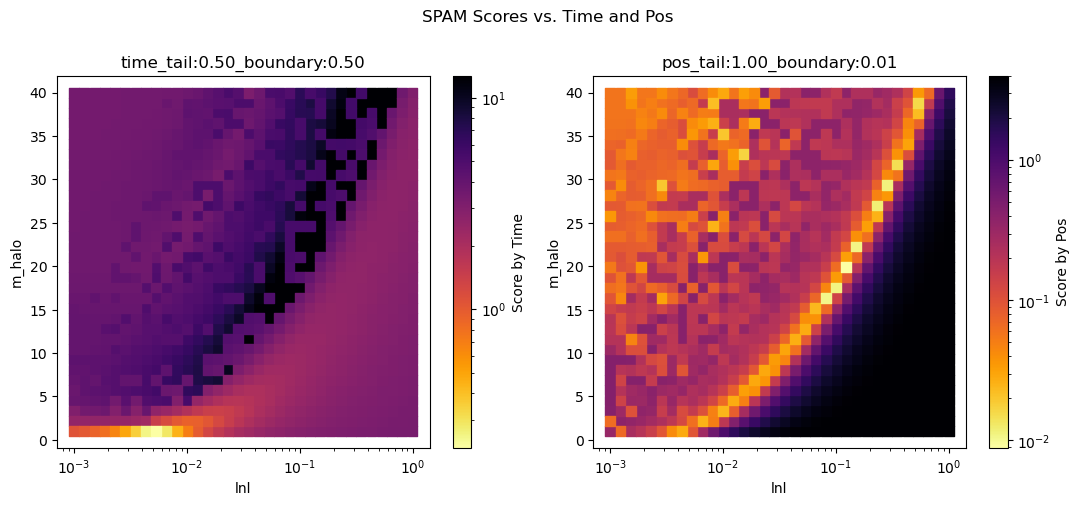

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

if buildEnv:
    # Define default scores
    time_col = 'time_tail:0.50_boundary:0.50'
    pos_col = 'pos_tail:1.00_boundary:0.01'
    input_cols = ['lnl', 'm_halo']

    # Remove top outliers of time score (90% quantile)
    time_q = v3_df[time_col].quantile(0.95)
    pos_q = v3_df[pos_col].quantile(0.90)

    # Sort data by time_col in descending order
    v3_df_sorted_time = v3_df.sort_values(by=time_col, ascending=False)

    # Create scatter plot for time_col
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))

    # set main title
    fig.suptitle('SPAM Scores vs. Time and Pos')

    fig.tight_layout(pad=2.0)

    sc = ax[0].scatter(
        v3_df_sorted_time[input_cols[0]], v3_df_sorted_time[input_cols[1]],
        c=v3_df_sorted_time[time_col], cmap='inferno_r',
        norm=mcolors.LogNorm(vmin=np.min(v3_df[time_col]), vmax=time_q),
        marker='s',
        s=50
    )
    ax[0].set_xlabel(input_cols[0])
    ax[0].set_ylabel(input_cols[1])
    ax[0].set_title(time_col)
    ax[0].set_xscale('log')
    fig.colorbar(sc, ax=ax[0], label='Score by Time')

    # Sort data by pos_col in descending order
    v3_df_sorted_pos = v3_df.sort_values(by=pos_col, ascending=False)

    # Create scatter plot for pos_col
    sc = ax[1].scatter(
        v3_df_sorted_pos[input_cols[0]], v3_df_sorted_pos[input_cols[1]],
        c=v3_df_sorted_pos[pos_col], cmap='inferno_r',
        norm=mcolors.LogNorm(vmin=np.min(v3_df[pos_col]), vmax=pos_q),
        marker='s',
        s=50,
    )
    ax[1].set_xlabel(input_cols[0])
    ax[1].set_ylabel(input_cols[1])
    ax[1].set_title(pos_col)
    ax[1].set_xscale('log')
    fig.colorbar(sc, ax=ax[1], label='Score by Pos')

    plt.show()


# Gridsearch v5, Score v3
Score_Pos is doing exactly what I expected.  It's degenerate, and changing both inputs in the right way will gives good results.

Score_Time is better.   It clearly has a local minumum, right at the edge of my gridsearch.  Therefore I need to adjust my gridseach to include more lnl values, and do smaller spacing perhaps. 

Time:2025-02-12 11:09:40,452 - [optimization_manager.__init__] - INFO - Initializing Space Manager
Time:2025-02-12 11:09:40,456 - [optimization_manager.__init__] - INFO - Space Manager Initialized


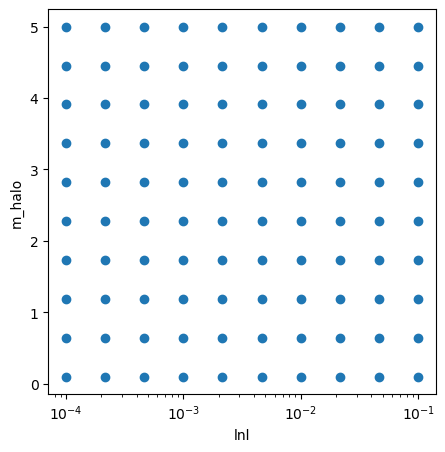

In [13]:
if buildEnv:

    # Use my optimizer class to do parameter limits and gridsearch

    # Define parameters
    parameter_space = [
        {'name':'lnl', 'bounds': [1e-4, 1e-1], 'prior':'log-uniform' }, # Working
        {'name':'m_halo', 'bounds': [1e-1, 5], 'prior':'uniform'  }, # Working
    ]

    # Create space manager
    space_manager = om.SpaceManager(parameter_space)

    # Set location for data
    data_dir = os.path.abspath( PROJECT_DIRECTORY + '/../data/spam_tuner_gridsearch_v6' )

    # create directory if not present
    if not os.path.exists(data_dir):
        os.makedirs(data_dir)
    
    # save parameter space in file
    space_manager.save_space_details(data_dir + '/parameter_space.json')

    # Get gridsearch of parameters
    grid_samples = space_manager.get_mesh_grid_points( n_pts_per_dim = 10 )


    # Scatter samples to show even distribution
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    ax.scatter(grid_samples[:,0], grid_samples[:,1])
    ax.set_xlabel('lnl')
    ax.set_ylabel('m_halo')
    ax.set_xscale('log')
    plt.show()



In [ ]:

if buildEnv:

    # Get scoring function up and running
    p1 = 62000000190717
    hand_spam_param = { 'name':'Hand-Found','m_halo': 6.4, 'lnl': 0.007 }
    tng_wrapper = st.POST_GRIDSEARCH_SCORING_ANALYSIS( p1, tail_range = [0.75], boundary_range = [0.1] )

    # Starting test
    if True:
        hand_orbit, _ = tng_wrapper.tng_target.simulate_orbit( hand_spam_param )
        print( f"Hand Orbit: {hand_orbit.shape}")

    # Loop through gridsearch, saving orbits while

    # Test scoring function


Time:2025-02-12 11:09:40,836 - [spam_tuner_tng_targets.__init__] - INFO - Creating Wrapper for Post Gridsearch Scoring: 62000000190717
Time:2025-02-12 11:09:40,838 - [convert_tng_to_spam.__init__] - INFO - Initializing TNG Target Class...
